# EDA Provincial — Demanda Electrica por Provincia

Este notebook complementa al EDA nacional (`notebooks/eda.ipynb`, guiado por `eda_organizacion.md`). Todo lo que ya se analizo alli (calidad general del dataset nacional, demanda diaria, forma vs nivel, calendario, clima, outliers y eventos sociales) aplica tambien aca y no se repite.

La diferencia central es que ahora la unidad de analisis es el sistema completo de 22 provincias:

```text
fecha | buenos_aires_01 | buenos_aires_02 | ... | tucuman_24
```

Esto habilita analisis nuevos que no eran posibles con el dato nacional agregado: calidad provincial, distribucion espacial, shares provinciales, correlaciones entre provincias, heterogeneidad, relacion con indicadores socioeconomicos, clima por provincia y PCA sobre el vector provincial completo.

El objetivo del notebook es quedarse con los resultados mas importantes para informar decisiones de modelado del CVAE: si conviene modelar el sistema completo, que features deberian entrar en `c`, que provincias pueden ser mas dificiles y si tiene sentido probar un experimento alternativo con shares.


In [37]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [43]:
from pathlib import Path
import os
import sys


def find_repo_root(start: Path) -> Path:
    """Walk upwards from start until the folder with provincias/ and src/ is found."""
    current = start
    for _ in range(5):
        if (current / "provincias").exists() and (current / "src").exists():
            return current
        current = current.parent
    raise FileNotFoundError("No se encontro la raiz del repositorio")


project_root = find_repo_root(Path.cwd())
sys.path.append(str(project_root))

os.environ["MPLCONFIGDIR"] = str(project_root / ".matplotlib_cache")
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

import pandas as pd

from provincias.src.provincial_data_quality import (
    build_provincial_quality_summary,
    load_provincial_datasets,
    load_national_hourly_demand,
)
from provincias.src.provincial_spatial_distribution import (
    compute_participation_by_hour,
    compute_participation_by_month,
    compute_participation_by_season,
    compute_province_participation,
    plot_participation_barplot,
    plot_participation_heatmap_by_hour,
    plot_participation_heatmap_by_month,
    plot_typical_day_stacked_area,
    summarize_top_province_concentration,
)
from provincias.src.provincial_eda_analysis import (
    build_socioeconomic_demand_table,
    build_split_diagnostics,
    compare_shares_on_extreme_days,
    compute_daily_energy_correlation,
    compute_monthly_temperature,
    plot_absolute_vs_share_profile,
    plot_calendar_profiles_selected,
    plot_climate_demand_examples,
    plot_correlation_heatmap,
    plot_daily_energy_boxplot,
    plot_mean_profiles_grid,
    plot_pca_explained,
    plot_pca_loading_heatmap,
    plot_pca_scores_by_month,
    plot_province_scatter,
    plot_share_variability,
    plot_socioeconomic_scatter,
    plot_split_diagnostics,
    plot_temperature_heatmap,
    plot_train_group_count_histogram,
    run_provincial_pca,
    summarize_climate_demand_by_province,
    summarize_group_count_risk,
    summarize_heterogeneity,
    summarize_pca_loadings,
    summarize_province_correlations,
    summarize_share_variability,
    summarize_socioeconomic_correlations,
    summarize_train_group_counts,
)


## 1. Calidad del Dataset Provincial

Ademas de los chequeos generales del EDA nacional, aca verificamos lo especifico de tener 22 series simultaneas: que las 22 provincias esten presentes todos los dias, que no haya provincias con nulos o ceros sistematicos, y que la suma provincial coincida tanto con la columna `TOTAL` de los archivos crudos como con la serie nacional que ya se habia construido para el EDA general.

In [3]:
quality_summary = build_provincial_quality_summary(project_root)
quality_summary["date_coverage"]

{'start_date': datetime.date(2019, 1, 1),
 'end_date': datetime.date(2026, 4, 30),
 'observed_days': 2311,
 'expected_days': 2311,
 'missing_days': 0,
 'years_present': [2019, 2021, 2022, 2023, 2024, 2025, 2026]}

El dataset provincial cubre del 2019-01-01 al 2026-04-30, con 2.311 dias observados sobre 2.311 dias esperados (excluyendo 2020 por la anomalia de pandemia, tal como en el dataset nacional). No hay dias faltantes: la cobertura temporal esta completa para los 22 anios-provincia simultaneamente.

In [4]:
quality_summary["hours_per_day_counts"]

hora
24    2311
Name: count, dtype: int64

In [5]:
quality_summary["duplicate_hourly_records"]

0

Los 2.311 dias tienen exactamente 24 registros horarios cada uno, y no hay registros fecha-hora duplicados. Esto confirma que la base horaria provincial (`dataset_base_horario.csv`, 55.464 filas = 2.311 dias x 24 horas) esta completa para las 22 provincias a la vez.

In [6]:
quality_summary["missing_by_province"]

,provincia,valores_faltantes,dias_afectados,primera_fecha_afectada,ultima_fecha_afectada
0,catamarca,1,1,2023-12-17,2023-12-17
1,jujuy,1,1,2023-12-17,2023-12-17
2,san_luis,1,1,2023-03-01,2023-03-01


Solo 3 valores nulos en todo el dataset, concentrados en 2 fechas puntuales (2023-03-01 para San Luis, 2023-12-17 para Catamarca y Jujuy). Son huecos aislados de una sola hora en provincias chicas, no un problema sistematico de ninguna serie. Aunque los valores nulos son pocos y están concentrados en fechas puntuales, no se imputan. Para el entrenamiento de modelos neuronales se eliminarán los días completos afectados, ya que un único NaN dentro de un perfil diario de 528 dimensiones invalida toda la muestra. Estos días se guardarán en anomaly_log.csv para ser reutilizados luego como casos de referencia en la etapa de detección de anomalías.

In [7]:
quality_summary["zero_values_by_province"]

,provincia,valores_cero,valores_negativos,primera_fecha_cero,ultima_fecha_cero
0,jujuy,1,0,2019-06-16,2019-06-16
1,la_pampa,10,0,2019-06-16,2019-06-16
2,la_rioja,6,0,2019-06-16,2019-06-16
3,san_luis,7,0,2019-06-16,2019-06-16
4,santa_cruz,6,0,2019-06-16,2019-06-16
5,tucuman,5,0,2019-06-16,2019-06-16


Los valores cero aparecen concentrados en el 2019-06-16 y afectan simultáneamente a varias provincias chicas. Por tratarse de un patrón anómalo y no de una variación normal de demanda, ese día se excluye del entrenamiento y se registra en anomaly_log.csv.

In [8]:
quality_summary["raw_total_consistency"]

,fuente,registros,provincias_encontradas,diferencia_absoluta_media_mwh,diferencia_absoluta_maxima_mwh,registros_con_diferencia_mayor_a_1_mwh
0,2019_2022,35064,22,0.106223,0.6,0
1,2023_2026,29184,22,0.250709,0.5,0


Comparando la suma de las 22 provincias contra la columna `TOTAL` de cada archivo crudo original, la diferencia absoluta media es de apenas 0,11-0,25 MWh, con un maximo de 0,6 MWh en mas de 64.000 registros. Estas diferencias son consistentes con redondeo de datos y no representan un problema real: la columna `TOTAL` de CAMMESA y la suma de provincias describen la misma cantidad.

In [9]:
quality_summary["provincial_sum_vs_national_series"]

,registros_comparados,diferencia_absoluta_media_mwh,diferencia_absoluta_maxima_mwh,diferencia_pct_media,diferencia_pct_maxima,registros_con_diferencia_mayor_a_1pct
0,46704,0.471292,32.442,0.003025,0.138426,0


La comparacion contra la serie nacional (`dataset_base_horario.csv` de la raiz del proyecto, construida de forma independiente a partir de otro archivo fuente) tambien confirma consistencia: sobre 46.704 registros horarios en el periodo 2021-2026, la diferencia porcentual promedio es de 0,003% y la maxima es de 0,14% (equivalente a unos 32 MWh en una hora de diciembre de 2022, sobre una demanda de mas de 20.000 MWh). Ninguna hora supera el 1% de diferencia. Esto valida que el dataset provincial y el nacional describen el mismo sistema electrico real, construidos desde fuentes distintas.

**Conclusion de la seccion 1**: el dataset provincial esta completo (22 provincias, todos los dias, sin huecos estructurales), es internamente consistente (la suma de provincias coincide con el TOTAL crudo y con la serie nacional) y solo tiene anomalias puntuales y menores (3 nulos aislados, un dia con ceros simultaneos en provincias chicas). Esta en condiciones de usarse para modelar.

## 2. Distribucion Espacial de la Demanda

Este es el analisis nuevo respecto al EDA nacional: como se reparte el consumo electrico entre las 22 provincias, y si esa distribucion espacial es estable o cambia segun la hora del dia y la epoca del anio. Para esto trabajamos con el share de cada provincia sobre la demanda nacional en cada registro horario:

```text
share_provincia_hora = demanda_provincia_hora / demanda_total_hora
```

In [39]:
hourly_demand = load_provincial_datasets(project_root)["dataset_base_horario"]
participation = compute_province_participation(hourly_demand)
participation

,provincia,participacion_pct
0,buenos_aires,49.132397
1,santa_fe,9.245988
2,cordoba,7.550660
3,mendoza,4.357732
4,chubut,3.515503
5,entre_rios,2.808002
6,tucuman,2.375930
7,chaco,2.301535
8,corrientes,2.189433
9,misiones,1.922194


Buenos Aires concentra en promedio el 49,1% de la demanda electrica nacional, muy por encima de Santa Fe (9,2%) y Cordoba (7,6%), que son las siguientes en el ranking. Entre las tres provincias mas grandes concentran cerca de dos tercios del sistema (se calcula exactamente a continuacion). En el otro extremo, La Pampa, Jujuy y Santa Cruz participan con menos del 1% cada una: son provincias chicas cuyo aporte al sistema conjunto es marginal en terminos de nivel, aunque no necesariamente en terminos de variabilidad relativa.

In [11]:
top3_concentration = summarize_top_province_concentration(participation)
top3_concentration

65.92904546280782

Buenos Aires, Cordoba y Santa Fe concentran en conjunto casi el 66% de la demanda electrica nacional. Esto tiene una implicancia directa para el modelo generativo: el vector `x` de 528 dimensiones esta dominado en magnitud por un puñado de provincias, por lo que conviene evaluar el modelo por provincia (como plantea la seccion de evaluacion del proyecto) en lugar de mirar solo el error agregado, que va a estar naturalmente dominado por Buenos Aires.

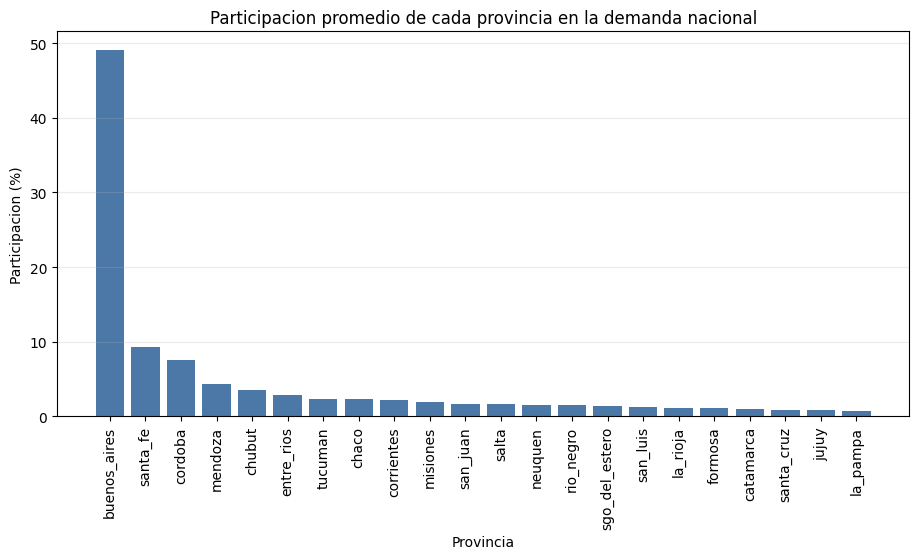

In [12]:
plot_participation_barplot(participation);

El grafico de barras confirma la fuerte heterogeneidad de tamaño entre provincias: la caida de participacion desde Buenos Aires hacia el resto del sistema es abrupta, y la mayoria de las provincias del interior participan con valores de un digito o menos. Esto es consistente con la geografia economica y demografica real de Argentina.

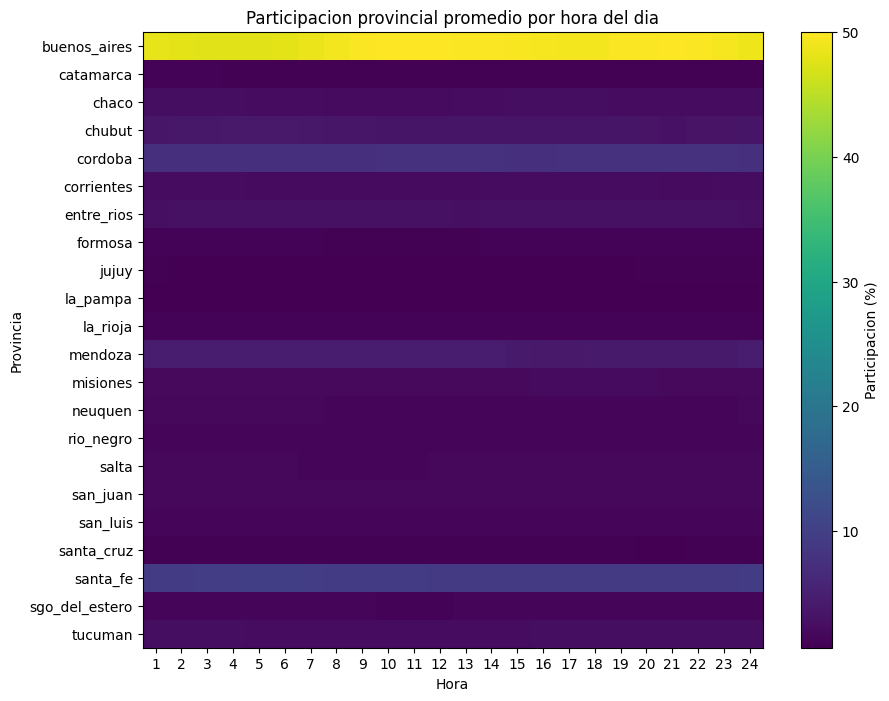

In [13]:
participation_by_hour = compute_participation_by_hour(hourly_demand)
plot_participation_heatmap_by_hour(participation_by_hour);

La participacion de cada provincia varia poco entre horas: para Buenos Aires, por ejemplo, el share horario promedio se mueve entre 47,9% (madrugada, hora 4-5) y 50,0% (media mañana, hora 11), una banda de apenas 2 puntos porcentuales. La distribucion espacial de la demanda es entonces bastante mas estable dentro del dia que el nivel total, que si tiene una forma horaria marcada (valle de madrugada, pico nocturno, segun el EDA nacional). Esto sugiere que la forma horaria del sistema es en gran medida un fenomeno nacional compartido, mas que un desacople entre provincias a lo largo del dia.

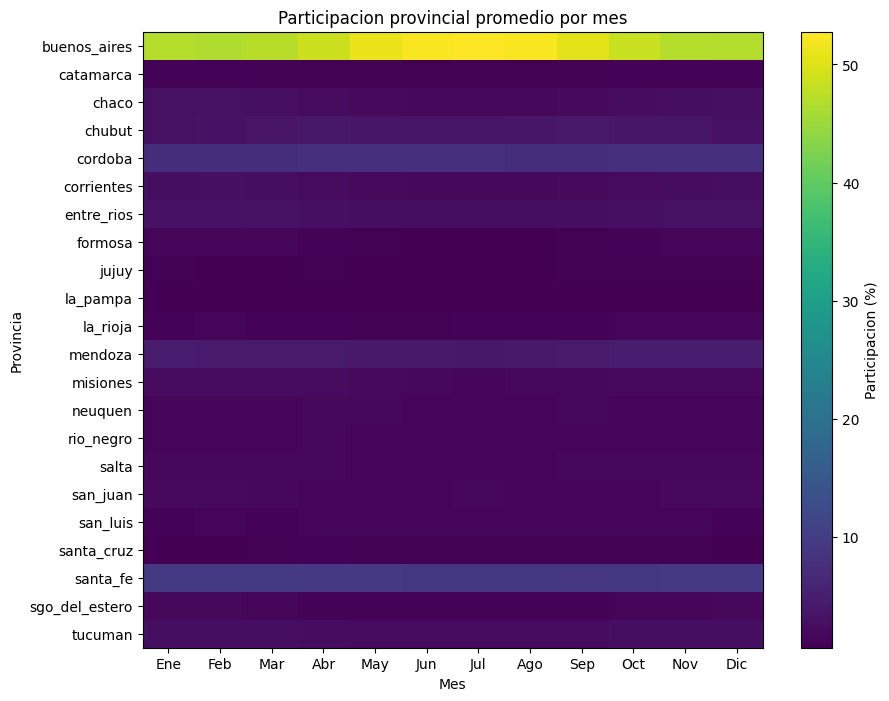

In [14]:
participation_by_month = compute_participation_by_month(hourly_demand)
plot_participation_heatmap_by_month(participation_by_month);

In [15]:
participation_by_season = compute_participation_by_season(hourly_demand)
participation_by_season[["buenos_aires", "cordoba", "santa_fe", "la_rioja", "santa_cruz"]].round(2)

,buenos_aires,cordoba,santa_fe,la_rioja,santa_cruz
estacion,,,,,
Verano,46.83,7.52,9.44,1.25,0.76
Otonio,48.95,7.54,9.35,1.06,0.95
Invierno,52.42,7.54,9.03,1.03,0.90
Primavera,48.54,7.62,9.13,1.23,0.95


A diferencia de la hora del dia, la estacion del anio si mueve la distribucion espacial de forma notoria. La participacion de Buenos Aires sube de 46,8% en verano a 52,4% en invierno, una diferencia de mas de 5 puntos porcentuales, mientras que provincias del norte con clima calido (como La Rioja) y del sur con clima frio (como Santa Cruz) ganan participacion relativa en verano. Una lectura razonable es que el uso de aire acondicionado en verano aumenta mas que proporcionalmente la demanda relativa en provincias del norte de clima calido, mientras que en invierno el peso del area metropolitana de Buenos Aires (con una base de consumo residencial y comercial mucho mayor) se hace mas dominante. Esto valida la necesidad de incluir clima e indicadores por provincia en el vector condicional `c`, en lugar de asumir una distribucion espacial fija.

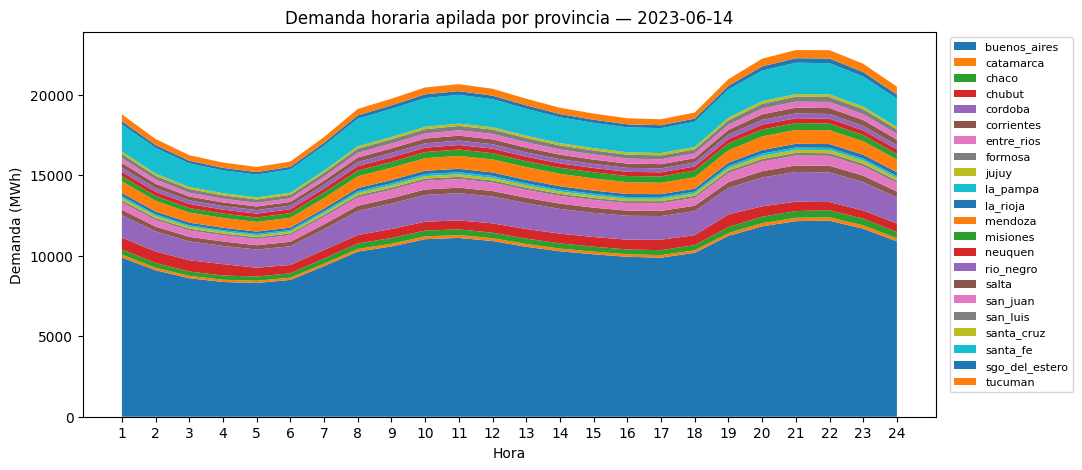

In [16]:
plot_typical_day_stacked_area(hourly_demand, "2023-06-14");

El grafico apilado de un miercoles habil de invierno (14/06/2023, sin feriado) muestra visualmente la composicion del sistema hora a hora: la banda de Buenos Aires domina el grafico en todo momento, y el resto de las provincias se apilan en franjas mucho mas finas y relativamente constantes en espesor a lo largo del dia. Esto es consistente con el hallazgo de la seccion anterior: la forma horaria del sistema completo esta dominada por la forma horaria de Buenos Aires, con contribuciones proporcionalmente estables del resto de las provincias dentro de un mismo dia.

**Conclusion de la seccion 2**: el sistema electrico argentino esta fuertemente concentrado en pocas provincias (Buenos Aires, Cordoba y Santa Fe explican cerca del 66% de la demanda), y esa concentracion es muy estable dentro del dia pero cambia de forma marcada entre estaciones, con un corrimiento hacia Buenos Aires en invierno y hacia provincias de clima calido en verano. Esto confirma que modelar el sistema conjunto (en lugar de provincias independientes) tiene sentido porque hay estructura espacial compartida, pero tambien que el modelo va a necesitar clima e indicadores socioeconomicos por provincia para capturar estos corrimientos estacionales en la distribucion del consumo, no solo el nivel nacional total.

Nota: no se incluye un mapa de Argentina coloreado por consumo porque el repositorio no cuenta con un archivo geografico (shapefile o GeoJSON) de las provincias; el ranking de participacion y los heatmaps provincia x hora / provincia x mes cubren el mismo objetivo de forma tabular.

## 3. Shares Provinciales

En esta seccion miramos el vector normalizado de participaciones provinciales. La pregunta no es solo cuanta energia consume cada provincia, sino cuanto pesa dentro del sistema en cada hora. Esto sirve como candidato alternativo para el `x` del CVAE si se quiere modelar distribucion espacial y luego reescalar por demanda total.


In [17]:
share_variability = summarize_share_variability(hourly_demand)
share_variability.round(3).head(10)


,provincia,share_medio_pct,share_std_pct,share_p05_pct,share_p95_pct,rango_p90_pct,cv_share
0,buenos_aires,49.132,3.126,43.914,53.893,9.979,0.064
3,chubut,3.516,0.770,2.412,4.916,2.503,0.219
19,santa_fe,9.246,0.689,8.139,10.409,2.271,0.075
2,chaco,2.302,0.659,1.549,3.566,2.018,0.287
4,cordoba,7.551,0.481,6.778,8.292,1.514,0.064
5,corrientes,2.189,0.483,1.586,3.095,1.509,0.221
11,mendoza,4.358,0.434,3.711,5.050,1.339,0.100
12,misiones,1.922,0.380,1.321,2.558,1.237,0.198
20,sgo_del_estero,1.346,0.398,0.927,2.161,1.233,0.296
21,tucuman,2.376,0.353,1.971,3.060,1.089,0.149


Buenos Aires es la provincia con mayor variabilidad absoluta de share porque tambien domina el nivel del sistema: su rango P5-P95 ronda 10 puntos porcentuales. Entre las provincias medianas y chicas se destacan Chubut, Chaco y Santa Fe. En terminos relativos, los shares de varias provincias pequenas son mas inestables que los de las grandes, aunque su impacto agregado sea menor.


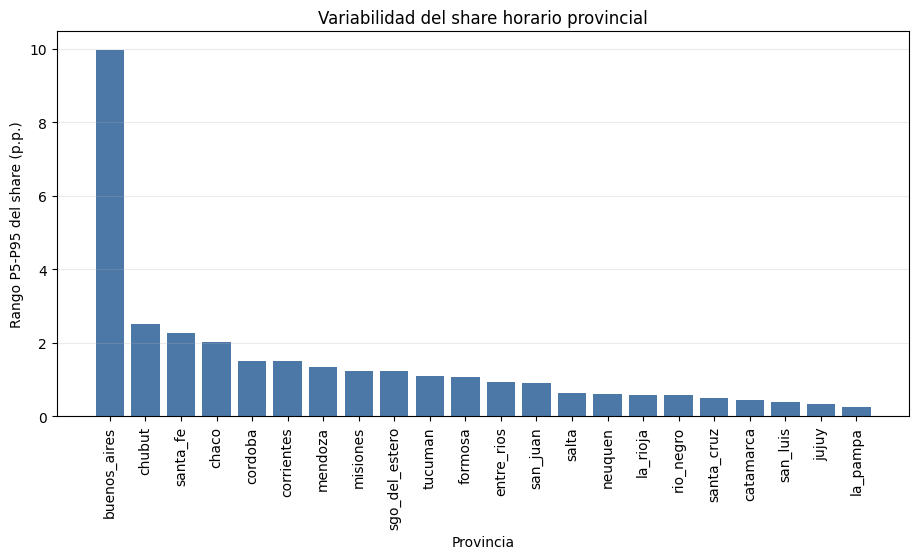

In [18]:
plot_share_variability(share_variability);


In [19]:
extreme_share_comparison = compare_shares_on_extreme_days(hourly_demand)
extreme_share_comparison.round(3).head(8)


,provincia,share_promedio_pct,share_max_demanda_2024-02-01,share_min_demanda_2019-06-16,dif_max_vs_promedio,dif_min_vs_promedio
3,chubut,3.516,2.219,4.287,-1.296,0.772
16,san_juan,1.717,2.174,2.437,0.457,0.720
18,santa_cruz,0.888,0.476,0.620,-0.412,-0.268
20,sgo_del_estero,1.346,1.756,0.915,0.410,-0.430
0,buenos_aires,49.132,49.437,46.588,0.305,-2.545
6,entre_rios,2.808,3.096,5.400,0.288,2.592
21,tucuman,2.376,2.637,2.534,0.261,0.158
13,neuquen,1.579,1.320,0.870,-0.259,-0.709


El dia de maxima demanda del sistema es 2024-02-01, consistente con el EDA nacional. En ese dia los cambios de share no son uniformes: algunas provincias calidas ganan peso relativo y otras, como Chubut, pierden participacion. Esto muestra que el share no es fijo y que el clima provincial puede mover la distribucion territorial.


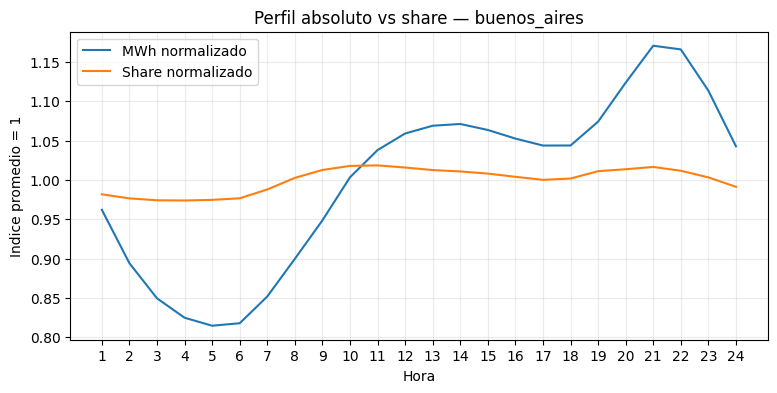

In [20]:
plot_absolute_vs_share_profile(hourly_demand, "buenos_aires");


Comparar MWh contra share ayuda a separar dos fenomenos: el perfil absoluto conserva la forma diaria de demanda, mientras que el share muestra cuanto cambia la dominancia relativa de la provincia dentro del sistema. Para el CVAE, modelar shares puede facilitar el aprendizaje de la distribucion espacial, pero no reemplaza completamente el modelado en MWh porque se pierde el nivel total.


## 4. Correlaciones Entre Provincias

El CVAE provincial modela las 22 provincias juntas. Por eso conviene verificar si hay dependencias estructurales entre provincias o si seria razonable modelarlas por separado.


In [21]:
province_correlation = compute_daily_energy_correlation(hourly_demand)
correlation_summary = summarize_province_correlations(province_correlation)
correlation_summary.round(3).head(8)


,provincia,correlacion_media_con_resto,correlacion_minima,provincia_menos_correlacionada,correlacion_maxima,provincia_mas_correlacionada
6,entre_rios,0.662,-0.213,santa_cruz,0.916,santa_fe
10,la_rioja,0.642,-0.232,santa_cruz,0.940,catamarca
21,tucuman,0.642,-0.174,santa_cruz,0.924,catamarca
4,cordoba,0.641,0.086,santa_cruz,0.916,santa_fe
16,san_juan,0.639,-0.258,santa_cruz,0.901,mendoza
1,catamarca,0.634,-0.162,santa_cruz,0.940,la_rioja
15,salta,0.631,-0.084,santa_cruz,0.901,jujuy
19,santa_fe,0.627,-0.060,santa_cruz,0.916,entre_rios


In [22]:
correlation_summary.round(3).tail(6)


,provincia,correlacion_media_con_resto,correlacion_minima,provincia_menos_correlacionada,correlacion_maxima,provincia_mas_correlacionada
12,misiones,0.466,-0.267,santa_cruz,0.811,corrientes
7,formosa,0.463,-0.436,santa_cruz,0.958,chaco
14,rio_negro,0.444,0.061,santa_cruz,0.778,neuquen
13,neuquen,0.396,0.066,formosa,0.778,rio_negro
3,chubut,-0.021,-0.241,formosa,0.388,santa_cruz
18,santa_cruz,-0.112,-0.436,formosa,0.388,chubut


La estructura no es uniforme. Provincias del centro y litoral, como Entre Rios, Cordoba, Santa Fe, La Rioja y Tucuman, tienen correlaciones medias altas con el resto. En cambio Chubut y Santa Cruz se comportan de manera mucho mas independiente e incluso muestran correlaciones negativas con varias provincias del norte. Esto justifica modelar el sistema completo, pero tambien evaluar por provincia porque hay subestructuras regionales.


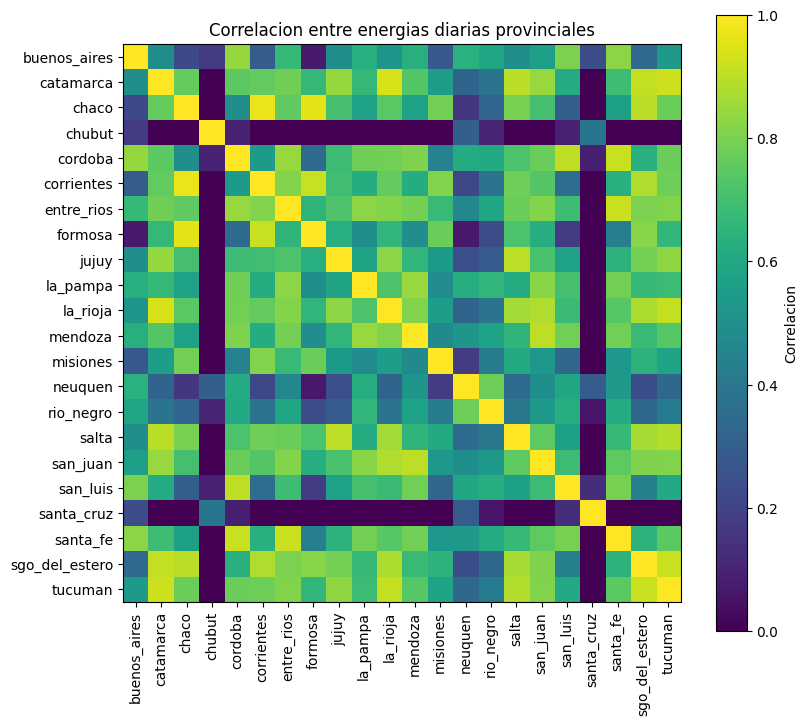

In [23]:
plot_correlation_heatmap(province_correlation);


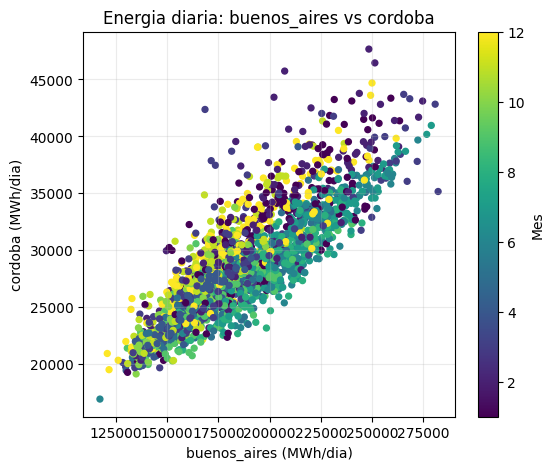

In [24]:
plot_province_scatter(hourly_demand, "buenos_aires", "cordoba");


Buenos Aires y Cordoba se mueven juntas en nivel diario, con separacion visible por mes. Esto refuerza que buena parte de la variabilidad es nacional/estacional compartida, no ruido independiente de cada provincia.


## 5. Heterogeneidad Provincial

Las provincias tienen escalas muy distintas. Esta seccion resume que provincias son mas grandes, cuales son mas volatiles y si la forma horaria promedio cambia mucho entre ellas.


In [25]:
heterogeneity = summarize_heterogeneity(hourly_demand)
heterogeneity.round(3).head(8)


,provincia,energia_media_diaria_mwh,energia_mediana_diaria_mwh,energia_std_diaria_mwh,cv_energia_diaria,ratio_max_min_promedio,hora_pico_modal
20,sgo_del_estero,5121.901,4479.4,1726.073,0.337,1.743,21
7,formosa,4026.428,3596.8,1330.515,0.330,1.613,20
2,chaco,8712.510,7670.0,2751.116,0.316,1.706,22
5,corrientes,8278.021,7464.1,2186.064,0.264,1.588,21
16,san_juan,6510.138,6130.7,1497.388,0.230,2.385,22
21,tucuman,8985.019,8415.0,1815.157,0.202,1.658,21
10,la_rioja,4298.671,4119.4,868.147,0.202,1.746,22
6,entre_rios,10633.322,10105.1,2113.679,0.199,1.511,21


In [26]:
heterogeneity.round(3).tail(6)


,provincia,energia_media_diaria_mwh,energia_mediana_diaria_mwh,energia_std_diaria_mwh,cv_energia_diaria,ratio_max_min_promedio,hora_pico_modal
15,salta,6192.366,5993.5,914.957,0.148,1.589,21
8,jujuy,3030.905,2960.4,387.110,0.128,1.608,21
11,mendoza,16282.118,15971.4,1974.283,0.121,1.374,22
14,rio_negro,5640.559,5635.6,604.332,0.107,1.609,21
18,santa_cruz,3267.151,3276.0,308.581,0.094,1.310,22
13,neuquen,5871.608,5838.9,549.901,0.094,1.770,22


Las provincias mas volatiles en energia diaria son Santiago del Estero, Formosa y Chaco, todas con coeficientes de variacion altos. En el extremo estable aparecen Neuquen, Santa Cruz, Rio Negro y Mendoza. Esto sugiere que la dificultad del modelo no depende solo del tamano: algunas provincias chicas o medianas tienen dinamicas relativamente ordenadas, mientras que otras tienen fuerte sensibilidad estacional.


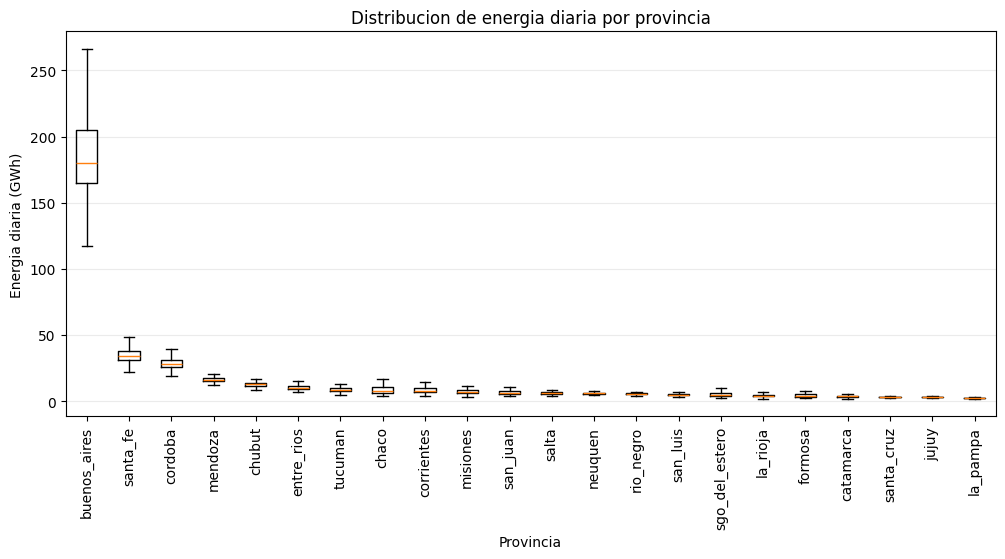

In [27]:
plot_daily_energy_boxplot(hourly_demand);


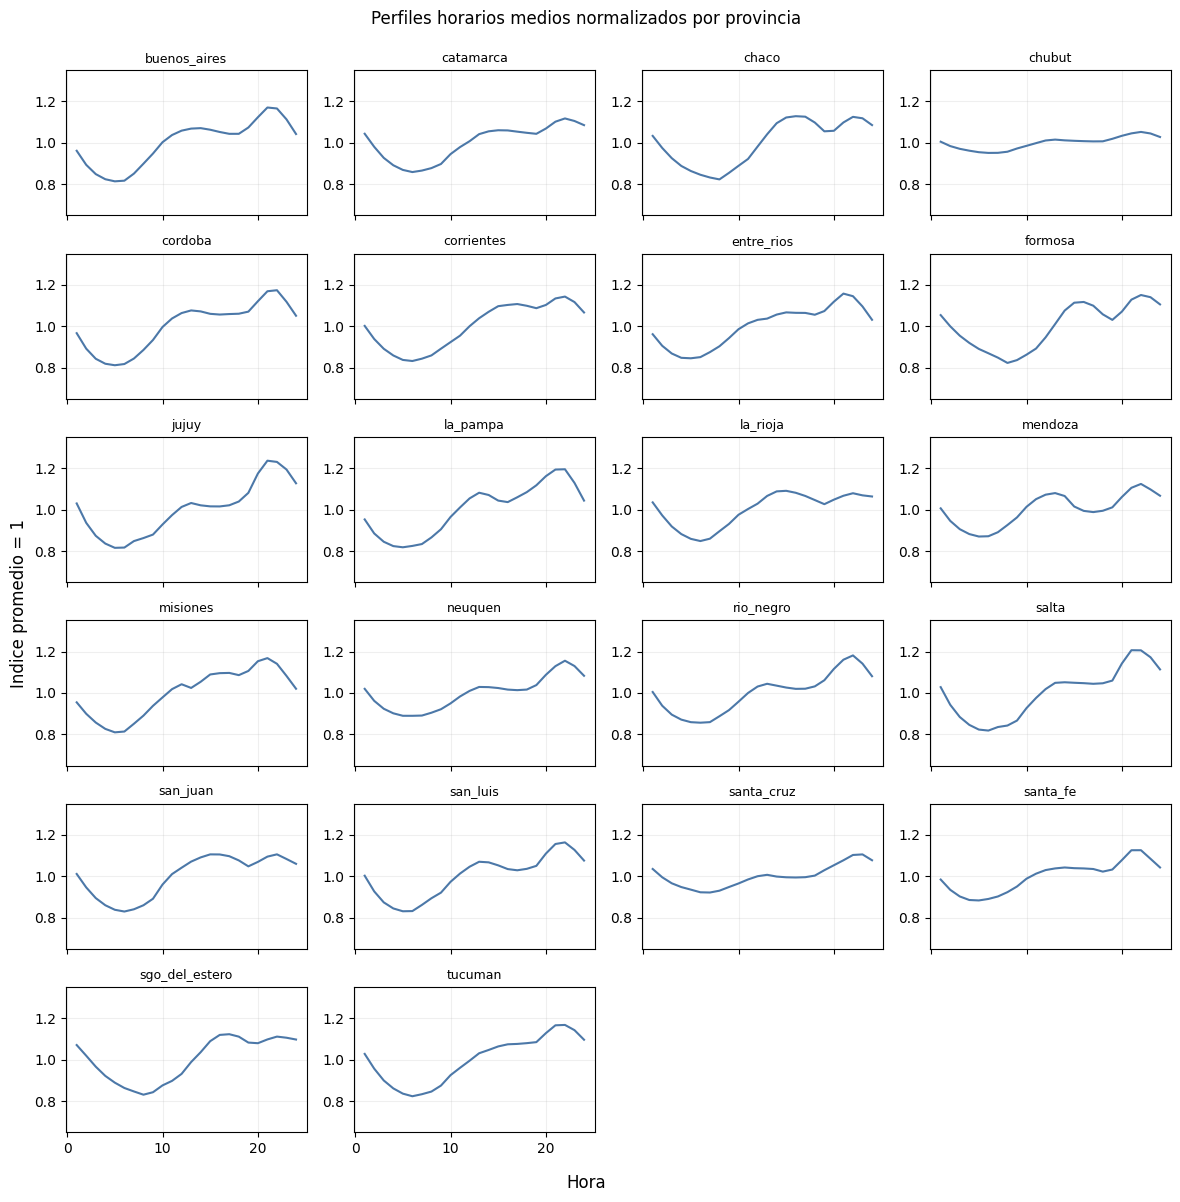

In [28]:
plot_mean_profiles_grid(hourly_demand);


La forma horaria promedio es parecida en muchas provincias, con pico nocturno dominante, pero no identica. Las diferencias de amplitud y hora pico justifican evaluar perfiles por provincia y no solo el vector completo de 528 dimensiones.


## 6. Relacion Indicadores Socioeconomicos -> Demanda

Los indicadores provinciales propuestos para `c` deberian explicar diferencias estructurales entre provincias. Aca se valida si poblacion, PBG per capita, participacion industrial y superficie tienen relacion con el consumo promedio.


In [29]:
indicators = pd.read_csv(project_root / "provincias" / "data" / "processed" / "indicadores_provinciales.csv")
socioeconomic_demand = build_socioeconomic_demand_table(hourly_demand, indicators)
socioeconomic_demand.sort_values("energia_media_diaria_mwh", ascending=False).round(4).head(8)


,provincia,poblacion,pbg_per_capita,participacion_industrial,superficie_km2,energia_media_diaria_mwh,consumo_mwh_por_habitante_dia
0,buenos_aires,20645703,15282.3208,0.2331,306113.3,185691.8171,0.0090
19,santa_fe,3544908,13616.0910,0.2600,133249.1,34890.5608,0.0098
4,cordoba,3840905,13461.0548,0.1805,164707.8,28575.0282,0.0074
11,mendoza,2043540,9723.3777,0.2333,149069.2,16282.1182,0.0080
3,chubut,592621,19408.2832,0.1544,224302.3,12926.7480,0.0218
6,entre_rios,1425578,11808.3500,0.1527,78383.7,10633.3220,0.0075
21,tucuman,1731820,6864.3203,0.1438,22592.1,8985.0194,0.0052
2,chaco,1129606,8621.9749,0.0804,99763.3,8712.5098,0.0077


In [30]:
socioeconomic_correlations = summarize_socioeconomic_correlations(socioeconomic_demand)
socioeconomic_correlations.round(3)


,energia_media_diaria_mwh,poblacion,pbg_per_capita,participacion_industrial,superficie_km2,consumo_mwh_por_habitante_dia
energia_media_diaria_mwh,1.000,0.996,0.126,0.327,0.593,0.101
poblacion,0.996,1.000,0.088,0.317,0.564,0.028
pbg_per_capita,0.126,0.088,1.000,-0.233,0.504,0.437
participacion_industrial,0.327,0.317,-0.233,1.000,-0.062,0.169
superficie_km2,0.593,0.564,0.504,-0.062,1.000,0.441
consumo_mwh_por_habitante_dia,0.101,0.028,0.437,0.169,0.441,1.000


La poblacion explica casi completamente el ranking de consumo medio provincial: la correlacion con energia media diaria es 0,996. El PBG per capita no explica tanto el nivel absoluto, pero si aporta informacion sobre consumo por habitante. Participacion industrial tiene correlacion positiva moderada y puede ayudar a distinguir provincias de poblacion similar.


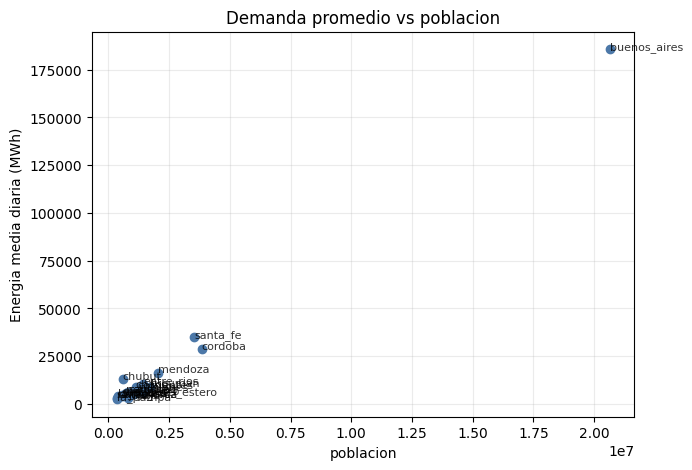

In [31]:
plot_socioeconomic_scatter(socioeconomic_demand, "poblacion");


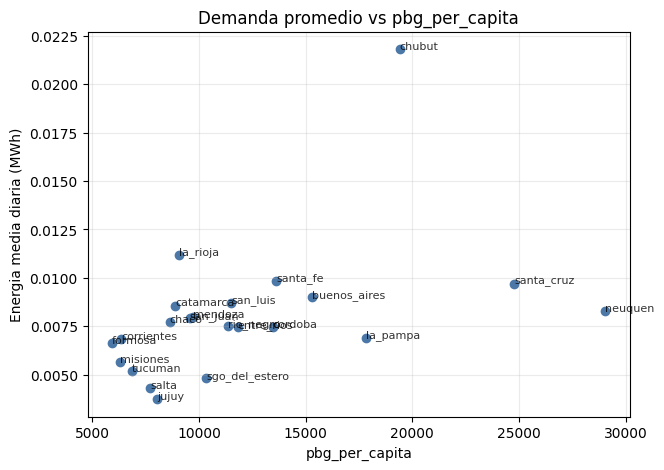

In [32]:
plot_socioeconomic_scatter(socioeconomic_demand, "pbg_per_capita", y="consumo_mwh_por_habitante_dia");


Para el modelo, poblacion deberia entrar si o si como feature estructural. PBG per capita y participacion industrial agregan senal distinta: no reemplazan a la poblacion, pero pueden explicar por que algunas provincias consumen mas o menos por habitante que lo esperado.


## 7. Clima por Provincia

A diferencia del EDA nacional, ahora cada provincia tiene su propio clima. Esto permite medir si la sensibilidad al calor y al frio cambia territorialmente.


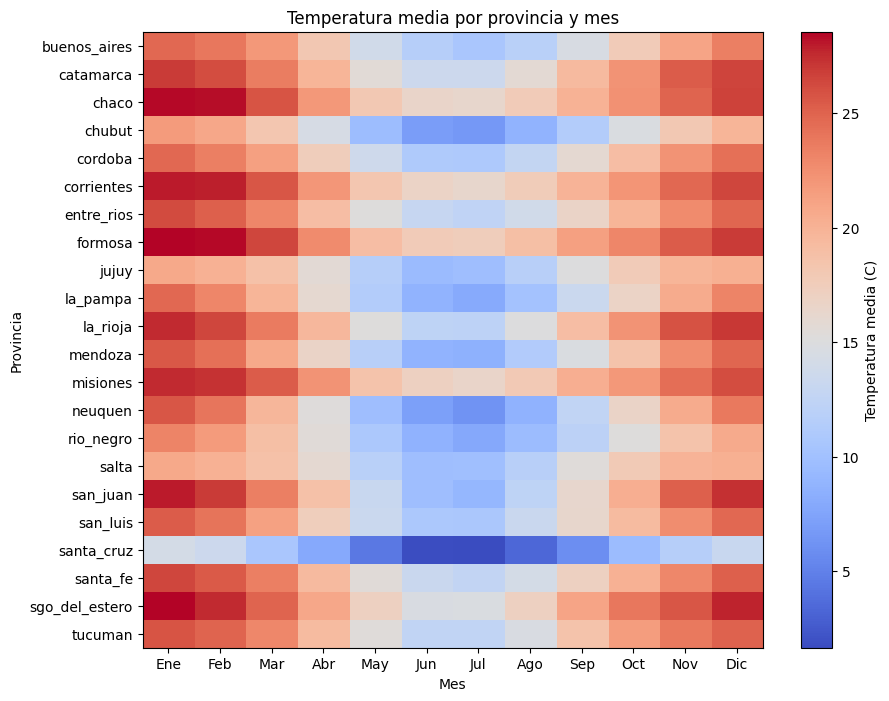

In [33]:
climate_daily = pd.read_csv(
    project_root / "provincias" / "data" / "processed" / "clima_diario_por_provincia.csv",
    parse_dates=["fecha"],
)
monthly_temperature = compute_monthly_temperature(climate_daily)
plot_temperature_heatmap(monthly_temperature);


In [34]:
climate_demand_summary = summarize_climate_demand_by_province(hourly_demand, climate_daily)
climate_demand_summary.round(3).head(8)


,provincia,corr_temp_media,corr_grado_calor,corr_grado_frio,dias_con_calor,dias_con_frio
7,formosa,0.824,0.932,-0.175,1456,220
2,chaco,0.773,0.925,-0.110,1304,283
5,corrientes,0.727,0.913,-0.062,1281,273
20,sgo_del_estero,0.724,0.893,-0.058,1217,337
16,san_juan,0.553,0.858,-0.011,953,747
21,tucuman,0.529,0.834,0.070,941,523
9,la_pampa,0.541,0.828,-0.150,566,1004
6,entre_rios,0.539,0.818,-0.015,869,577


In [35]:
climate_demand_summary.round(3).tail(6)


,provincia,corr_temp_media,corr_grado_calor,corr_grado_frio,dias_con_calor,dias_con_frio
8,jujuy,0.369,0.461,-0.004,223,903
17,san_luis,0.071,0.457,0.306,760,751
0,buenos_aires,-0.127,0.448,0.538,667,778
15,salta,0.443,0.421,-0.070,217,902
18,santa_cruz,-0.601,0.008,0.602,4,2075
3,chubut,-0.293,-0.054,0.319,289,1201


El efecto del calor es muy fuerte en Formosa, Chaco, Corrientes y Santiago del Estero, con correlaciones altas entre `grado_calor` y energia diaria. En Patagonia la relacion cambia: Santa Cruz casi no tiene dias de calor y su demanda se asocia mucho mas al frio. Buenos Aires queda en una zona mixta, donde tanto calor como frio aportan informacion.


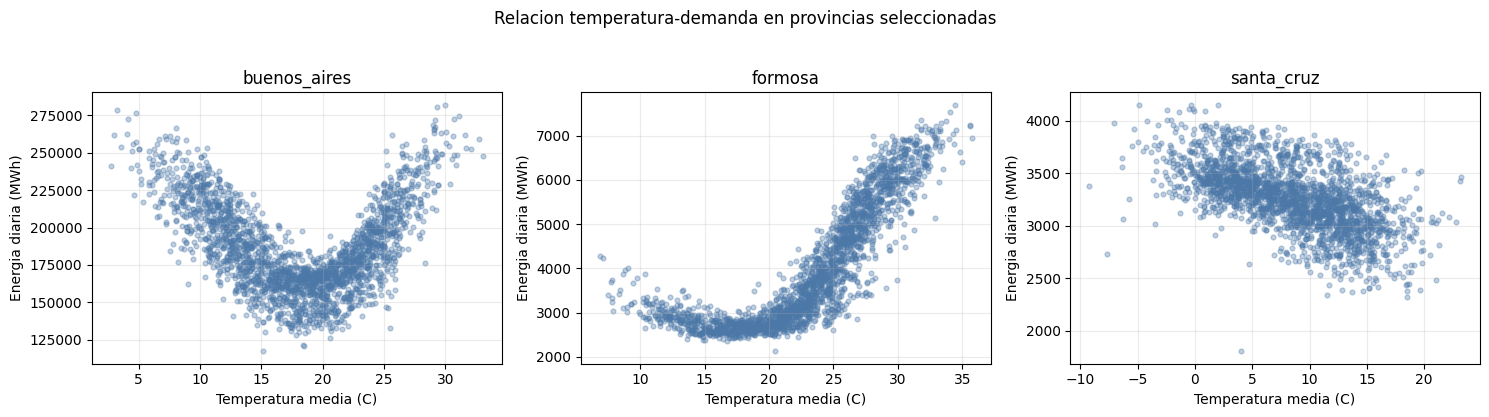

In [36]:
plot_climate_demand_examples(
    hourly_demand,
    climate_daily,
    ["buenos_aires", "formosa", "santa_cruz"],
);


La heterogeneidad climatica provincial aporta informacion que el clima nacional agregado no puede capturar. Para el CVAE, esto respalda usar clima por provincia en `c`, al menos con agregados diarios como primera version.


## 8. PCA sobre el Vector x Provincial

Aplicamos PCA sobre el vector diario completo de 528 dimensiones. Este PCA se usa solo como analisis exploratorio, no como parte obligatoria del pipeline de modelado.


In [37]:
x_profiles = load_provincial_datasets(project_root)["x_perfiles_diarios"]
pca_result = run_provincial_pca(x_profiles, n_components=12)
pca_result["explained"].round(4)


,componente,varianza_explicada,varianza_acumulada
0,PC1,0.8244,0.8244
1,PC2,0.0778,0.9022
2,PC3,0.0402,0.9423
3,PC4,0.0250,0.9673
4,PC5,0.0074,0.9747
5,PC6,0.0038,0.9785
6,PC7,0.0036,0.9821
7,PC8,0.0030,0.9851
8,PC9,0.0025,0.9876
9,PC10,0.0016,0.9892


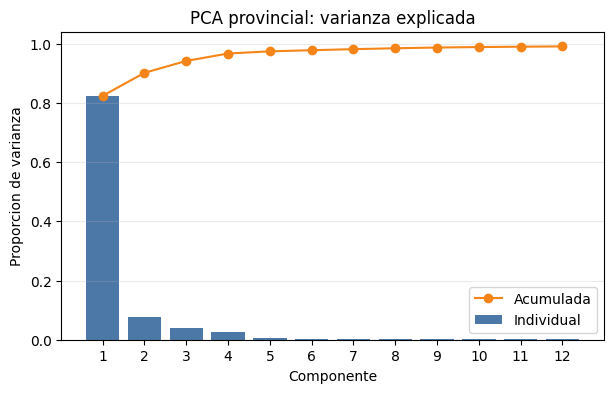

In [38]:
plot_pca_explained(pca_result["explained"]);


PC1 explica aproximadamente 82% de la varianza y PC1+PC2 superan el 90%. Igual que en el EDA nacional, el primer componente esta dominado por nivel general del sistema; la diferencia es que ahora ese nivel general incluye estructura espacial, no solo una curva de 24 horas.


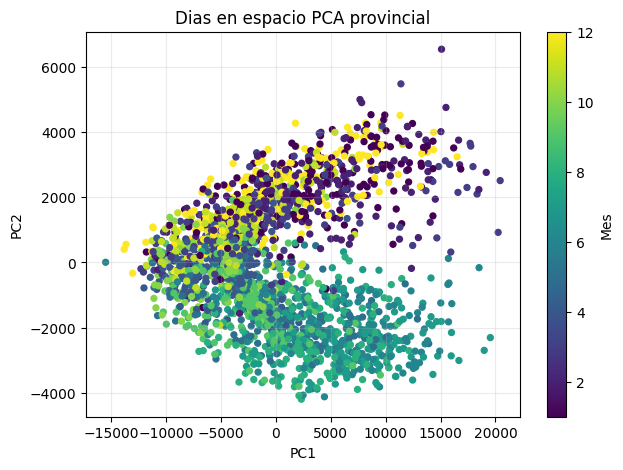

In [39]:
plot_pca_scores_by_month(pca_result);


In [40]:
summarize_pca_loadings(pca_result, component=1).round(5).head(8)


,provincia,loading_medio,loading_abs_medio,hora_mayor_abs
0,buenos_aires,0.19583,0.19583,16
19,santa_fe,0.03399,0.03399,15
4,cordoba,0.02645,0.02645,15
6,entre_rios,0.00993,0.00993,15
11,mendoza,0.00872,0.00872,16
21,tucuman,0.00690,0.00690,16
16,san_juan,0.00598,0.00598,16
5,corrientes,0.00486,0.00486,24


In [41]:
summarize_pca_loadings(pca_result, component=2).round(5).head(8)


,provincia,loading_medio,loading_abs_medio,hora_mayor_abs
0,buenos_aires,-0.03596,0.14901,17
19,santa_fe,0.04848,0.04905,16
2,chaco,0.04506,0.04506,16
5,corrientes,0.03491,0.03491,16
4,cordoba,0.02859,0.02984,17
6,entre_rios,0.02712,0.02712,16
20,sgo_del_estero,0.02660,0.02660,17
7,formosa,0.02280,0.02280,15


Los loadings de PC1 estan dominados por Buenos Aires, Santa Fe y Cordoba, que son tambien las provincias de mayor demanda. PC2 vuelve a tener mucho peso de Buenos Aires, pero aparecen con mas fuerza Santa Fe, Chaco y Corrientes, lo que sugiere un componente de redistribucion territorial/estacional mas que puro nivel.


## 8.1. Comparacion Train / Validation / Test

Como el split del proyecto es temporal, conviene revisar si validation y test tienen distribuciones parecidas a train. Este chequeo ayuda a interpretar fallas futuras del modelo: si 2025-2026 se corren respecto de train, el problema puede ser de cambio de distribucion y no solo de arquitectura.


In [44]:
split_diagnostics = build_split_diagnostics(hourly_demand, climate_daily, pca_result)
split_diagnostics.groupby("split")[[
    "demanda_total_mwh",
    "temp_media_pais",
    "PC1",
    "PC2",
    "buenos_aires",
    "share_top3_pct",
]].median().round(2)


,demanda_total_mwh,temp_media_pais,PC1,PC2,buenos_aires,share_top3_pct
split,,,,,,
test,382353.6,20.11,-411.23,351.50,48.26,64.95
train,362917.4,18.30,-1365.71,-259.99,49.33,66.28
validation,378548.9,19.36,-806.92,177.27,48.02,64.79


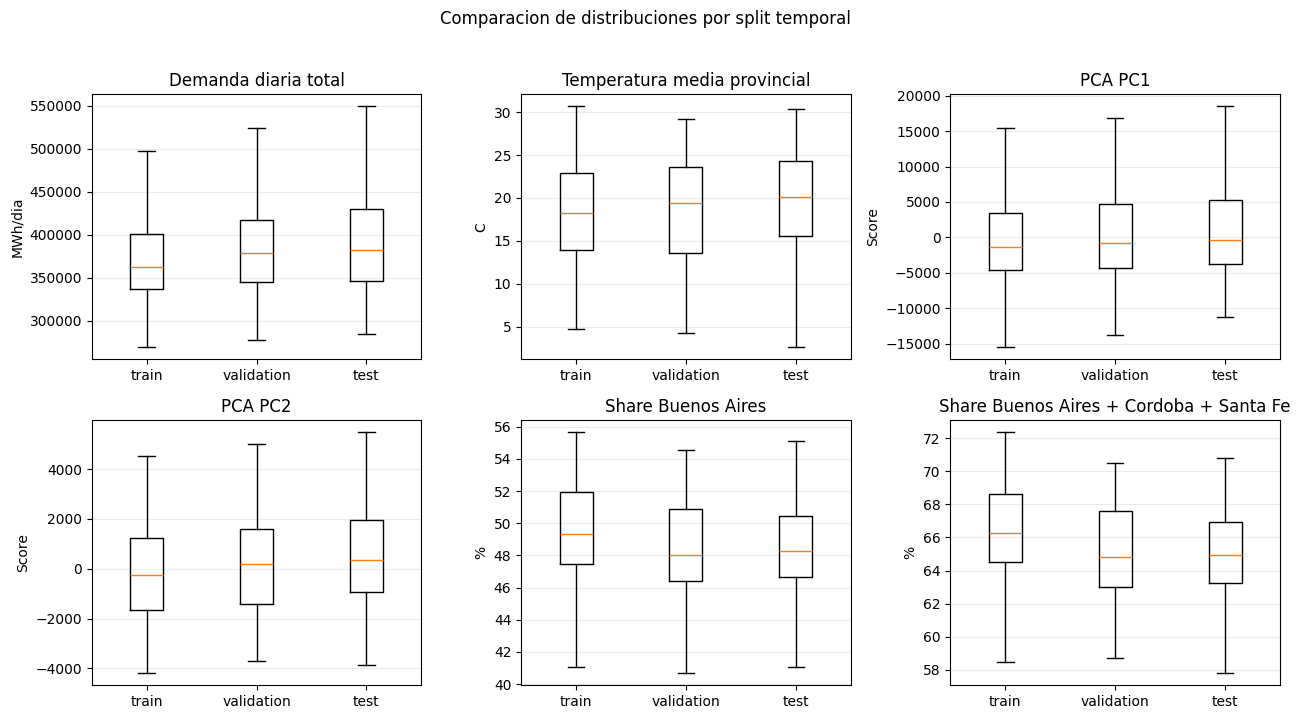

In [45]:
plot_split_diagnostics(split_diagnostics);


La comparacion queda alineada con el split del pipeline: train usa 2019 y 2021-2023, validation usa 2024 y test usa 2025-2026. Validation y test tienen demanda mediana mas alta que train y tambien se desplazan en PC1/PC2; ademas, el share conjunto de Buenos Aires, Cordoba y Santa Fe baja levemente frente a train. Si el modelo falla en test, este corrimiento temporal debe considerarse como posible cambio de distribucion.


## 8.2. Soporte de Grupos para Historical Mean y KDE

Los baselines historico y KDE condicionan por `(mes, dia_semana, es_feriado)`. Como hay hasta 168 grupos posibles, es importante saber cuantos dias de train tiene cada grupo antes de confiar en medias historicas o KDEs separados.


In [46]:
group_counts = summarize_train_group_counts(hourly_demand)
group_counts.head(12)


,mes,dia_semana,es_feriado,dias_train
83,6,6,1,0
107,8,4,1,0
105,8,3,1,0
103,8,2,1,0
101,8,1,1,0
97,7,6,1,0
95,7,5,1,0
91,7,3,1,0
109,8,5,1,0
89,7,2,1,0


In [47]:
summarize_group_count_risk(group_counts)


,umbral,grupos
0,<= 0,50
1,<= 1,70
2,<= 2,75
3,<= 3,79
4,<= 5,84
5,<= 10,84


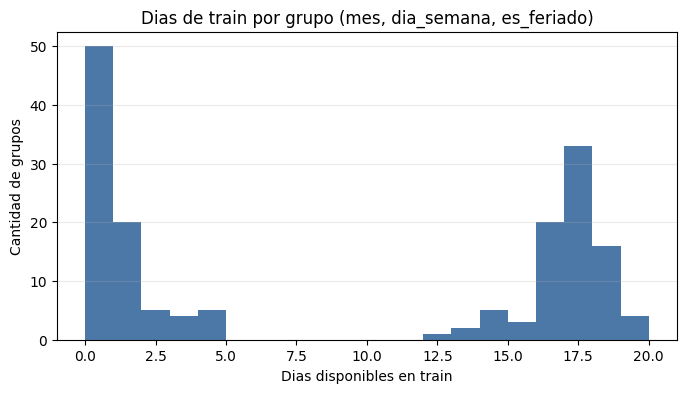

In [48]:
plot_train_group_count_histogram(group_counts);


Los grupos de feriados son los mas fragiles: 50 combinaciones no tienen ningun dia en train y 84 tienen cinco dias o menos. Para el baseline historico y especialmente para KDE conviene usar fallback jerarquico cuando el grupo tenga pocas muestras: `(mes, dia_semana, es_feriado)` -> `(mes, dia_semana)` -> `(mes)` -> promedio global.


## 8.3. Loadings PCA por Provincia-Hora

Las tablas de loadings resumen que provincias pesan mas en cada componente, pero el heatmap permite ver simultaneamente la estructura territorial y horaria.


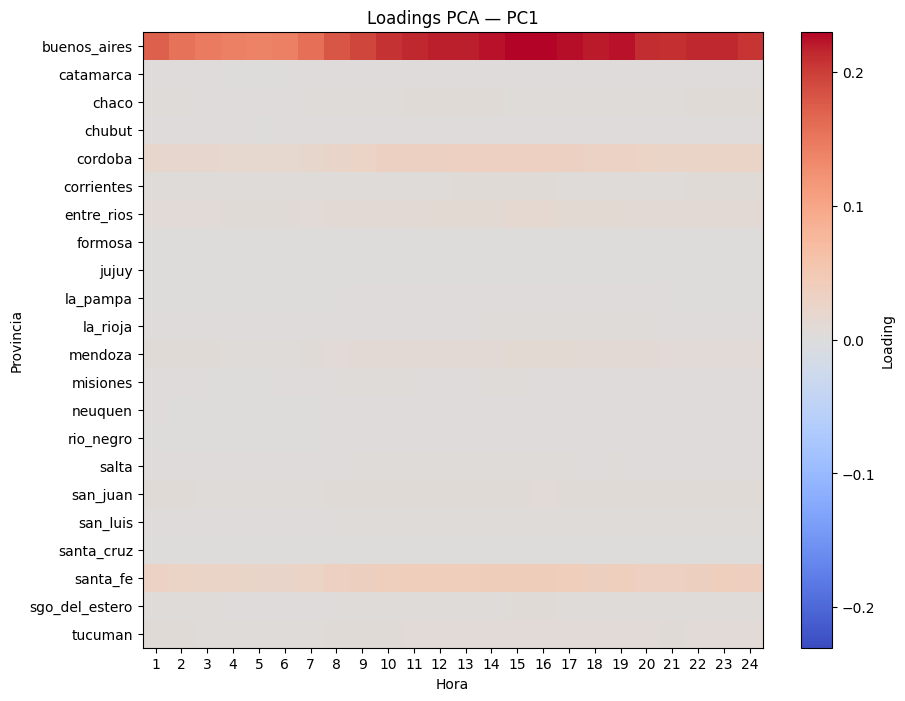

In [49]:
plot_pca_loading_heatmap(pca_result, component=1);


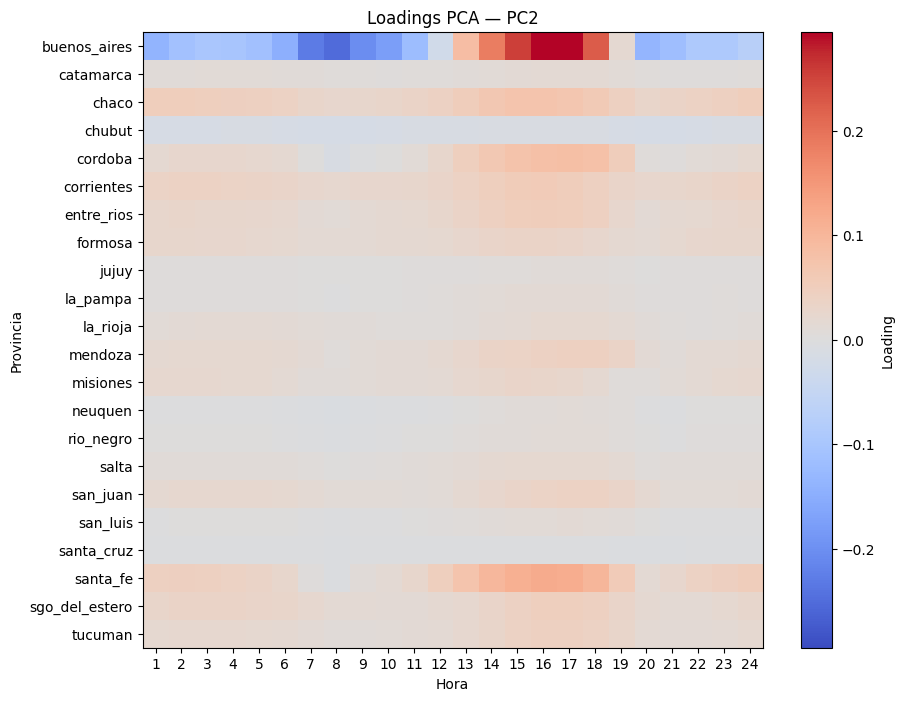

In [50]:
plot_pca_loading_heatmap(pca_result, component=2);


PC1 aparece como componente de nivel general, con mayor peso en las provincias grandes y en horas de alta demanda. PC2 ayuda a ver redistribuciones mas sutiles entre Buenos Aires y el resto del sistema, con una estructura horaria mas marcada.


## 8.4. Efecto Calendario Provincial

Como `c` incluye mes, dia de semana y feriado, mostramos una validacion minima del efecto calendario en provincias representativas. No se repite para las 22 provincias para mantener el notebook liviano.


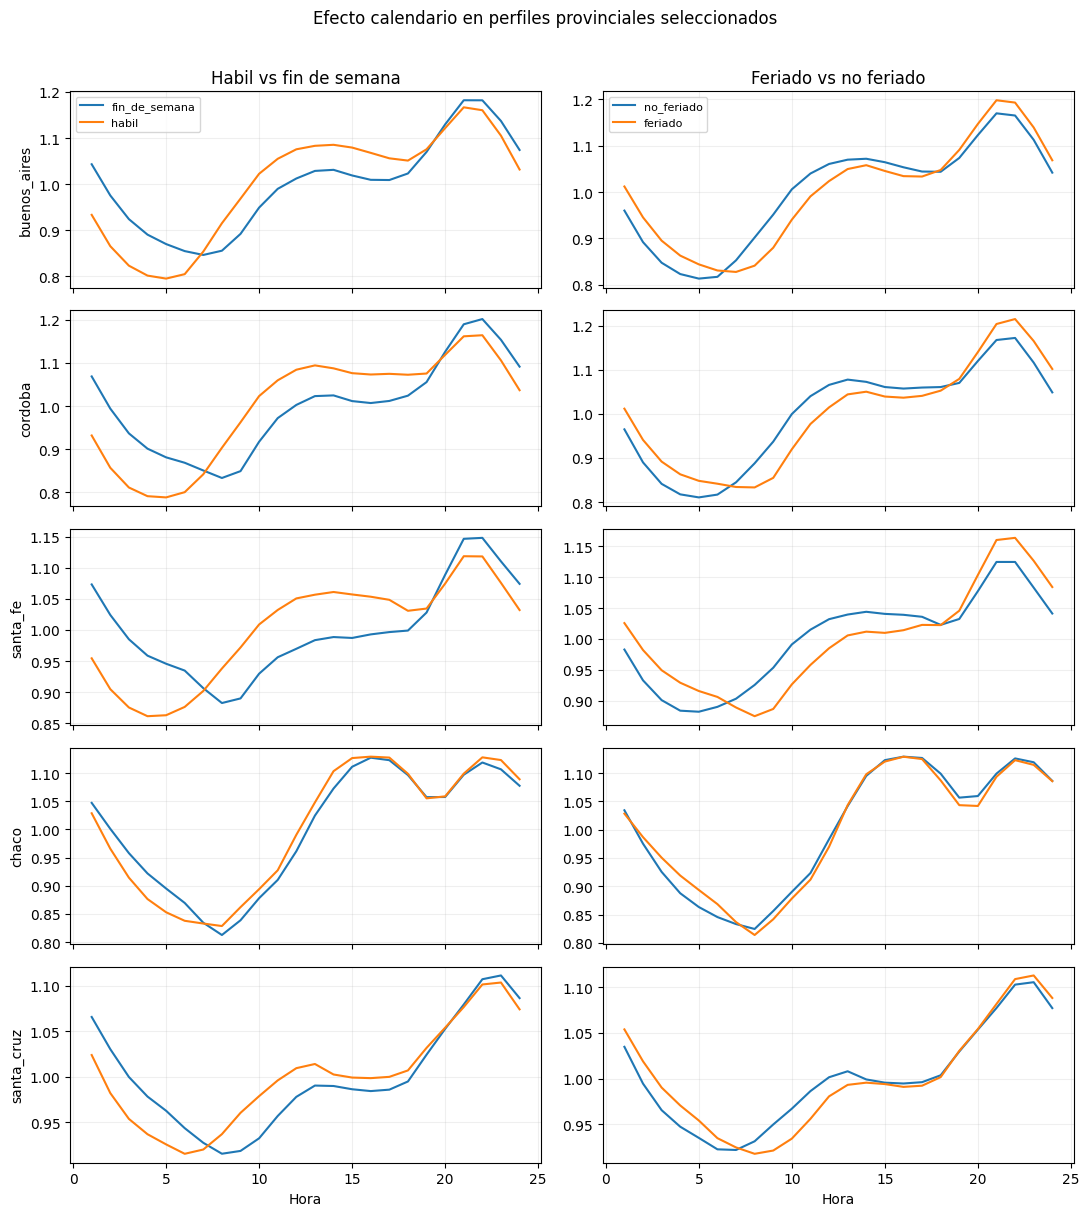

In [51]:
plot_calendar_profiles_selected(
    hourly_demand,
    ["buenos_aires", "cordoba", "santa_fe", "chaco", "santa_cruz"],
);


El calendario cambia la forma relativa del perfil, no solo el nivel. En las provincias grandes se ve con claridad la diferencia entre dias habiles y fines de semana, mientras que en provincias mas chicas la senal existe pero es mas ruidosa. Esto conecta directamente con el baseline historico por grupos de calendario.


## 9. Resultado Esperado del EDA Provincial

El EDA provincial confirma que el sistema esta muy concentrado: Buenos Aires, Cordoba y Santa Fe explican cerca de dos tercios de la demanda. Esa concentracion es bastante estable dentro del dia, pero cambia por estacion y por clima, por lo que no conviene asumir shares fijos.

Las provincias no son independientes. Hay un bloque centro-litoral/norte con correlaciones altas, mientras que Patagonia, especialmente Santa Cruz y Chubut, tiene dinamicas mas propias. Esto justifica entrenar un modelo conjunto, pero obliga a reportar metricas por provincia para no esconder errores de provincias pequenas bajo el peso de Buenos Aires.

Los indicadores socioeconomicos son utiles: poblacion explica el nivel absoluto, mientras que PBG per capita e industria agregan informacion para consumo relativo o por habitante. El clima provincial tambien agrega valor: el calor domina en el norte, el frio pesa mas en Patagonia y Buenos Aires queda en una zona mixta.

Para el modelado, quedan dos caminos defendibles: entrenar el CVAE sobre MWh para generar perfiles completos directamente, o hacer un experimento alternativo sobre shares provinciales y reescalar por demanda total. Ademas, los chequeos por split y por soporte de grupos muestran que la evaluacion temporal y los fallbacks de baselines son parte necesaria del diseno experimental. El PCA muestra que pocas componentes capturan gran parte de la varianza, pero tambien que el nivel domina; por eso la evaluacion debe mirar tanto error absoluto como distribucion provincial, cobertura por provincia y estabilidad de shares.
